# Generalised elliptical potential in `lenstronomy`

This notebook is a tutorial about the generalised elliptical potential ('GEP') profile in lenstronomy.

In [1]:
import numpy as np

from matplotlib import pyplot as plt

# Use TeX
from matplotlib import rc
rc('font', size=18)
rc('text', usetex=True)
rc('font', family='serif')

## Theory

The generalised elliptical potential profile describes a lens whose lensing potential has elliptical contours, whose centre, ellipticity, and poiting angle can vary smoothly with the radius. We thus choose to parameterise such elliptical isopotential contours with their **elliptical radius** $\zeta$.

The potential at a point ($x, y$) of the image plane thus reads
$$
\psi(x, y) = \psi[\zeta(x, y)]
$$
where $\zeta(x, y)$ is the elliptical radius of the ellipse where $(x, y)$ is. This function is implicitly determined by the functions that characterise the elliptical contours: the ellipticity $e(\zeta)$, pointing angle of the semi-major axis $\phi(\zeta)$ and the position of the centre $\boldsymbol{x}_{\rm c}(\zeta)$.

A given GEP profile is thus characterised by five functions: $e(\zeta)$, $\phi(\zeta)$, $x_{\rm c}(\zeta)$, $y_{\rm c}(\zeta)$ and of course the radial profile $\psi(\zeta)$. These functions must be chosen in the list of implemented models to be used in practice.

The profile code then takes care of turning all this into the usual lensing functions: $\psi(x, y)$, $\boldsymbol{\alpha}(x, y)$ and the Hessian $\partial_i\partial_j \psi(x, y)$.


## Using the profile

In [2]:
from lenstronomy.LensModel.lens_model import LensModel

The GEP profile is used just like the other lenstronomy profiles, except that **one must specify the models for ellipticity, position of the centre, etc.** in `profile_kwargs_list`.

In [3]:
lens_model_list = ['GEP']

GEP_models = {'parameterization': 'rectangular',
            'ellipticity_model': 'linear',
            'pointing_angle_model': None,
            'position_model': 'linear',
            'radial_potential': 'power_law'}

profile_kwargs_list = [GEP_models]

lens_model = LensModel(lens_model_list=lens_model_list,
                       profile_kwargs_list=profile_kwargs_list) # NB: change wrt usual models

In [7]:
lens_model.lens_model.func_list[0].lower_limit_default

{'e1_0': -1.0,
 'e2_0': -1.0,
 'e1_1': -1.0,
 'e2_1': -1.0,
 'center_x': -100,
 'center_y': 100,
 'v_x': -0.5,
 'v_y': -0.5,
 'theta_E': 0.01,
 'gamma': 1.5}

At the moment, the following profiles are supported. I'm still wondering whether this is the most efficient implementation, compared to $(e_1, e_2)$ for instance.

In [4]:
from lenstronomy.LensModel.Profiles.generalised_elliptical_potential import _supported_parameterizations, _supported_ellipticity_models, _supported_pointing_angle_models, _supported_position_models, _supported_radial_profiles

print(f"""
Parameterizations: {_supported_parameterizations}
Ellipticity models: {_supported_ellipticity_models}
Pointing angle models: {_supported_pointing_angle_models}
Drift models: {_supported_position_models}
Radial profiles: {_supported_radial_profiles}
""")


Parameterizations: ['rectangular', 'polar']
Ellipticity models: ['linear', 'quadratic', 'exponential']
Pointing angle models: ['linear', 'exponential', 'arctan']
Drift models: ['linear', 'quadratic']
Radial profiles: ['power_law', 'cored_power_law']



If you attempt to create a model with non-existing models, it will raise an error:

In [5]:
non_existing_GEP_models = {'ellipticity_model': 'nonsense',
            'pointing_angle_model': 'linear',
            'position_model': 'linear',
            'radial_potential': 'power_law'}

lens_model = LensModel(lens_model_list=['GEP'],
                       profile_kwargs_list=[non_existing_GEP_models])

ValueError: The ellipticity model nonsense is not valid.
                    Choose amongst:
                    ['linear', 'quadratic', 'exponential']

Once the model is set up you can check the required kwargs using the LensModel info() method.

In [6]:
lens_model.info()

Lens model 0 is GEP with parameters ['e1_0', 'e2_0', 'e1_1', 'e2_1', 'center_x', 'center_y', 'v_x', 'v_y', 'theta_E', 'gamma']


## Illustrations

Le us plot the potential, displacement angle and convence/shear for a given model.

In [7]:
# Choose the model kwargs

kwargs_GEP = {
'e1_0': 0.3, # ellipticity e1 of isopotential contours at zeta=0
'e2_0': -0.1, # ellipticity e2 of isopotential contours at zeta=0
'e1_1': -0.1, # derivative of e1 at zeta=0
'e2_1': 0.05, # derivative of e2 at zeta=0
'center_x': 0.0,
'center_y': 0.0,
'v_x': -0.03, # derivative of x of the ellipse centre with respect to zeta (drift rate along x)
'v_y': -0.05, # same along y
'theta_E': 1.2, # Einstein radius
'gamma': 2.1, # power-law index
}

kwargs_lens = [kwargs_GEP]

# Set a grid
x = np.linspace(-2, 2, 100) * kwargs_GEP['theta_E']
y = np.linspace(-2, 2, 100) * kwargs_GEP['theta_E']
X, Y = np.meshgrid(x, y)

### Potential

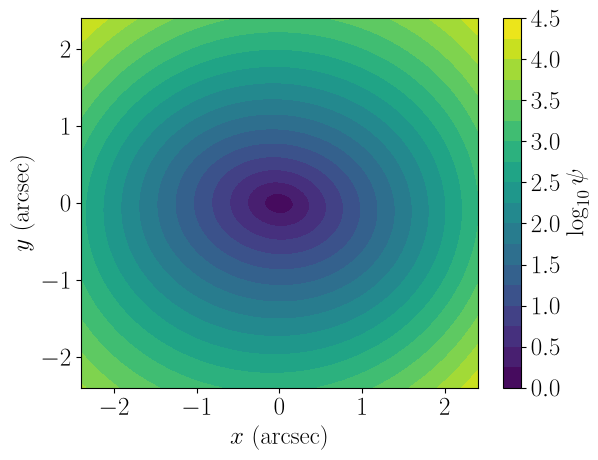

In [8]:
fig, ax = plt.subplots()

contours = ax.contourf(X, Y, lens_model.potential(X, Y, kwargs_lens), levels=20)
fig.colorbar(contours, ax=ax, label=r'$\log_{10}\psi$')
ax.set_xlabel(r"$x$ (arcsec)")
ax.set_ylabel(r"$y$ (arcsec)")

plt.show();

### Displacement angle

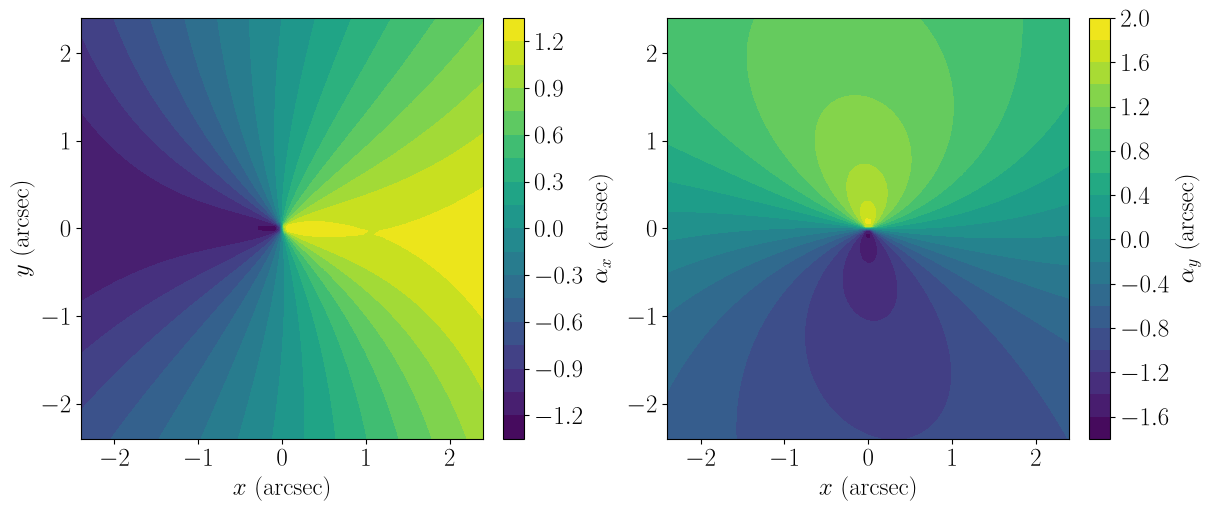

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")

alpha_x, alpha_y = lens_model.alpha(X, Y, kwargs_lens)

ax = axes[0]
contours = ax.contourf(X, Y, alpha_x, levels=20)
fig.colorbar(contours, ax=ax, label=r'$\alpha_x$ (arcsec)')
ax.set_xlabel(r"$x$ (arcsec)")
ax.set_ylabel(r"$y$ (arcsec)")

ax = axes[1]
contours = ax.contourf(X, Y, alpha_y, levels=20)
fig.colorbar(contours, ax=ax, label=r'$\alpha_y$ (arcsec)')
ax.set_xlabel(r"$x$ (arcsec)")

plt.show();

### Convergence and shear

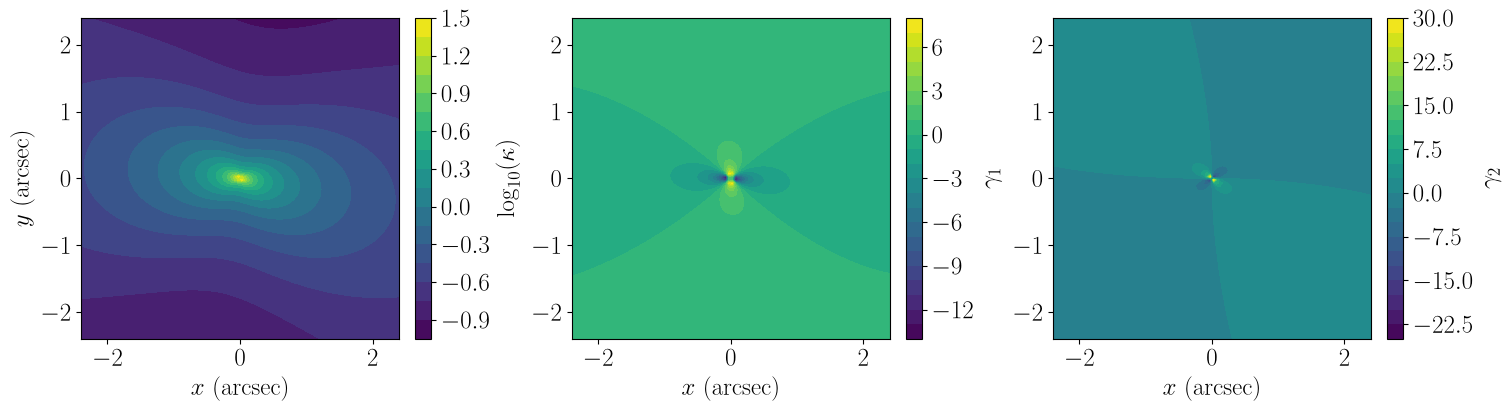

In [10]:
#fig, ax = plt.subplots()
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")

kappa = lens_model.kappa(X, Y, kwargs_lens)
gamma1, gamma2 = lens_model.gamma(X, Y, kwargs_lens)

ax = axes[0]
contours = ax.contourf(X, Y, np.log10(kappa), levels=20)
fig.colorbar(contours, ax=ax, label=r'$\log_{10}(\kappa)$')
ax.set_xlabel(r"$x$ (arcsec)")
ax.set_ylabel(r"$y$ (arcsec)")

ax = axes[1]
contours = ax.contourf(X, Y, gamma1, levels=20)
fig.colorbar(contours, ax=ax, label=r'$\gamma_1$')
ax.set_xlabel(r"$x$ (arcsec)")

ax = axes[2]
contours = ax.contourf(X, Y, gamma2, levels=20)
fig.colorbar(contours, ax=ax, label=r'$\gamma_2$')
ax.set_xlabel(r"$x$ (arcsec)")

plt.show();

## Example of parameter inference

In [11]:
import corner

### Create an image

In [20]:
from lenstronomy.SimulationAPI.sim_api import SimAPI
from lenstronomy.SimulationAPI.ObservationConfig.HST import HST

# source

source_model_list = ['SERSIC_ELLIPSE']

magnitude_source = 24.0

R_sersic_source = 0.03
n_sersic_source = 1.0
e1_source = -0.2
e2_source = 0.1
x_source = 0.1
y_source = -0.1

kwargs_sersic = {'magnitude': magnitude_source,
                 'R_sersic': R_sersic_source, 
                 'n_sersic': n_sersic_source, 
                 'e1': e1_source, 
                 'e2': e2_source, 
                 'center_x': x_source, 
                 'center_y': y_source}

kwargs_source_mag = [kwargs_sersic]

# lens: EPL + SHEAR

image_lens_model_list = ['EPL', 'SHEAR']

kwargs_EPL = {'theta_E': 1.0, 'gamma': 2.1, 'e1': 0.2, 'e2': 0.1}
kwargs_shear = {'gamma1': 0.02, 'gamma2': -0.03, 'ra_0': 0.0, 'dec_0': 0.0}

kwargs_lens = [kwargs_EPL, kwargs_shear]
profile_kwargs_list = [None, None]

# gather the full model
kwargs_model = {'lens_model_list': image_lens_model_list,
                'lens_profile_kwargs_list': profile_kwargs_list,
                'source_light_model_list': source_model_list}

# get the telescope settings for HST
psf = 'GAUSSIAN'
band = HST(band='WFC3_F160W', psf_type=psf) # this chooses the specific camera and filter of HST
kwargs_band = band.kwargs_single_band() # we are only considering a single band (i.e. a single wavelength/filter)
pixel_size = band.camera['pixel_scale'] # in arcsec

kwargs_psf = {'psf_type': psf,
              'fwhm': kwargs_band['seeing'],
              'pixel_size': pixel_size,
              'truncation': 5}

# define the numerics
kwargs_numerics = {'supersampling_factor': 1,
                   'supersampling_convolution': False}

# call the simulation API class
sim = SimAPI(num_pix = 49, # number of pixels we want in our image
             kwargs_single_band = kwargs_band, # give the SimAPI class the keyword arguments for HST that we got above
             kwargs_model = kwargs_model)

kwargs_data = sim.kwargs_data

# convert magnitudes into amplitudes
# we don't care about lens light or point source for the moment
_, kwargs_source, _ = sim.magnitude2amplitude(kwargs_source_mag=kwargs_source_mag)

# now use the SimAPI class to generate a noisy image in one step
imSim = sim.image_model_class(kwargs_numerics)

image = imSim.image(kwargs_lens = kwargs_lens,
                    kwargs_source = kwargs_source)

image_noisy = image + sim.noise_for_model(model = image)

kwargs_data['image_data'] = image_noisy

/Users/pfleury/Documents/GitHub/ELROND-project/lenstronomy/lenstronomy/LensModel/Profiles/epl.py:297: RuntimeWarning: invalid value encountered in divide
  R_omega = Z * hyp2f1(1, t / 2, 2 - t / 2, -(1 - q) / (1 + q) * (Z / Z.conj()))


/var/folders/pp/t8q3hnyx3ll7kcn8h_02ghfw0000gp/T/ipykernel_67660/3911142317.py:11: RuntimeWarning: invalid value encountered in log10
  im = ax.matshow(np.log10(image_noisy), origin='lower', vmin=v_min, vmax=v_max, cmap=cmap, extent=[0, 1, 0, 1])


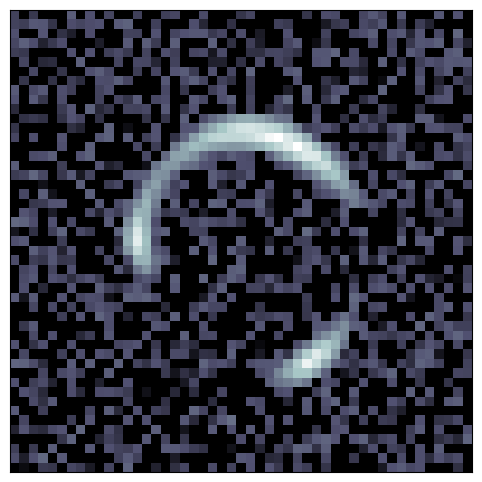

In [21]:
# plot the image
cmap_string = 'bone'
cmap = plt.get_cmap(cmap_string).copy()
cmap.set_bad(color='k', alpha=1.)
cmap.set_under('k')

v_min = -4
v_max = 1

f, ax = plt.subplots(1, 1, figsize=(6, 6), sharex=False, sharey=False)
im = ax.matshow(np.log10(image_noisy), origin='lower', vmin=v_min, vmax=v_max, cmap=cmap, extent=[0, 1, 0, 1])
ax.get_xaxis().set_visible(False)
ax.get_yaxis().set_visible(False)
ax.autoscale(False)

plt.show()

### Fit the image

In [ ]:
fitting_lens_model_list = ['GEP', 'SHEAR']

# initialise the lists of parameters
fixed_lens = []
kwargs_lens_init = []
kwargs_lens_sigma = []
kwargs_lower_lens = []
kwargs_upper_lens = []

# lens parameters
# specify which parameters are fixed 
# and choose the initial value, step size, lower and higher limits for the sampled parameters

# GEP
fitting_GEP_models = {
    'ellipticity_model': 'linear',
    'position_model': 'linear',
    'radial_potential': 'power_law'}
# when not specified, the parameterization is 'rectangular' by default

fixed_lens.append({'center_x': 0.0, 'center_y': 0.0})

kwargs_lens_init.append({
    'e1_0': kwargs_EPL['e1'], 'e1_1': 0.0,
    'e2_0': kwargs_EPL['e2'], 'e2_1': 0.0,
    'v_x': 0.0, 'v_y': 0.0,
    'theta_E': kwargs_EPL['theta_E'], 'gamma': kwargs_EPL['gamma']})

kwargs_lens_sigma.append({
    'e1_0': 0.01, 'e1_1': 0.01,
    'e2_0': 0.01, 'e2_1': 0.01,
    'v_x': 0.01, 'v_y': 0.01,
    'theta_E': 0.01, 'gamma': 0.01})

#kwargs_lower_lens = [lens_model.lens_model.func_list[0].lower_limit_default for model in ]

kwargs_lower_lens.append({
    'e1_0': -0.5, 'e1_1': -0.5,
    'e2_0': -0.5, 'e2_1': -0.5,
    'v_x': -0.5, 'v_y': -0.5,
    'theta_E': 0.01, 'gamma': 1.5})

kwargs_upper_lens.append({
    'e1_0': 0.5, 'e1_1': 0.5,
    'e2_0': 0.5, 'e2_1': 0.5,
    'v_x': 0.5, 'v_y': 0.5,
    'theta_E': 10, 'gamma': 2.5})

# shear
fixed_lens.append({'ra_0': 0.0, 'dec_0': 0.0})
kwargs_lens_init.append({'gamma1': 0.02, 'gamma2': -0.03})
kwargs_lens_sigma.append({'gamma1': 0.01, 'gamma2': 0.01})
kwargs_lower_lens.append({'gamma1': -0.5, 'gamma2': -0.5})
kwargs_upper_lens.append({'gamma1': 0.5, 'gamma2': 0.5})

lens_params = [kwargs_lens_init,
               kwargs_lens_sigma,
               fixed_lens,
               kwargs_lower_lens,
               kwargs_upper_lens]
fitting_profile_kwargs_list = [fitting_GEP_models, None]
#kwargs_lens_init

# now for the source
source_model_list = ['SERSIC_ELLIPSE']

fixed_source = []
kwargs_source_init = []
kwargs_source_sigma = []
kwargs_lower_source = []
kwargs_upper_source = []
fixed_source.append({})
import copy
kwargs_sersic_init = copy.deepcopy(kwargs_sersic)
kwargs_sersic_init.pop("magnitude")
kwargs_source_init.append(kwargs_sersic_init)
kwargs_source_sigma.append({'R_sersic': 0.001, 'n_sersic': 0.001, 'e1': 0.01, 'e2': 0.01,'center_x': 0.0001, 'center_y': 0.0001})
kwargs_lower_source.append({'R_sersic': 0.001, 'n_sersic': 0.5, 'e1': -0.5, 'e2': -0.5,'center_x': -10.0, 'center_y': -10.0})
kwargs_upper_source.append({'R_sersic': 10.0, 'n_sersic': 5.0,'e1': 0.5, 'e2': 0.5,'center_x': 10.0, 'center_y': 10.0})

source_params = [kwargs_source_init, kwargs_source_sigma,
                 fixed_source, kwargs_lower_source, kwargs_upper_source]

kwargs_params = {'lens_model': lens_params,
                'source_model': source_params}

In [ ]:
# run the MCMC
from lenstronomy.Workflow.fitting_sequence import FittingSequence

kwargs_likelihood = {'source_marg': True}

kwargs_model = {'lens_model_list': fitting_lens_model_list,
                'lens_profile_kwargs_list': fitting_profile_kwargs_list, # NB: this changes wrt to usual models
                'source_light_model_list': source_model_list}

multi_band_list = [[kwargs_data, kwargs_psf, kwargs_numerics]]

kwargs_data_joint = {'multi_band_list': multi_band_list,
                     'multi_band_type': 'multi-linear'}

kwargs_constraints = {}

fitting_seq = FittingSequence(kwargs_data_joint, kwargs_model, kwargs_constraints, kwargs_likelihood, kwargs_params)

fitting_kwargs_list = [['MCMC', {'n_burn': 2000, 'n_run': 5000, 'walkerRatio': 10, 'sigma_scale': 1.0}]]

chain_list = fitting_seq.fit_sequence(fitting_kwargs_list)
kwargs_result = fitting_seq.best_fit()

print("""Best-fit parameters:
{}
""".format(kwargs_result))

MCMC selected. Sampling with default option emcee.


100%|██████████| 7000/7000 [16:32<00:00,  7.05it/s]


Computing the MCMC...
Number of walkers =  160
Burn-in iterations:  2000
Sampling iterations (in current run): 7000
992.9722852706909 time taken for MCMC sampling
Best-fit parameters:
{'kwargs_lens': [{'e1_0': np.float64(0.12886222104965675), 'e2_0': np.float64(0.051066201536031364), 'e1_1': np.float64(-0.07585329045865155), 'e2_1': np.float64(0.13046187152039812), 'center_x': 0.0, 'center_y': 0.0, 'v_x': np.float64(0.007978831480591425), 'v_y': np.float64(-0.011919855123108542), 'theta_E': np.float64(0.9707108050922276), 'gamma': np.float64(2.081560443748172)}, {'gamma1': np.float64(-0.04864646212748161), 'gamma2': np.float64(0.08920707496446559), 'ra_0': 0.0, 'dec_0': 0.0}], 'kwargs_source': [{'amp': 1, 'R_sersic': np.float64(0.028721797022636518), 'n_sersic': np.float64(0.9962788878543875), 'e1': np.float64(-0.21256167946967003), 'e2': np.float64(0.08966944093031755), 'center_x': np.float64(0.10584013748297287), 'center_y': np.float64(-0.10879691531585411)}], 'kwargs_lens_light': []

/Users/pfleury/Documents/GitHub/ELROND-project/lenstronomy/lenstronomy/Plots/model_band_plot.py:218: RuntimeWarning: invalid value encountered in log10
  np.log10(self._data),


-1.1018778730052916 reduced X^2 of all evaluated imaging data combined (without degrees of freedom subtracted).
reduced chi^2 of data  0 =  1.1018778730052916


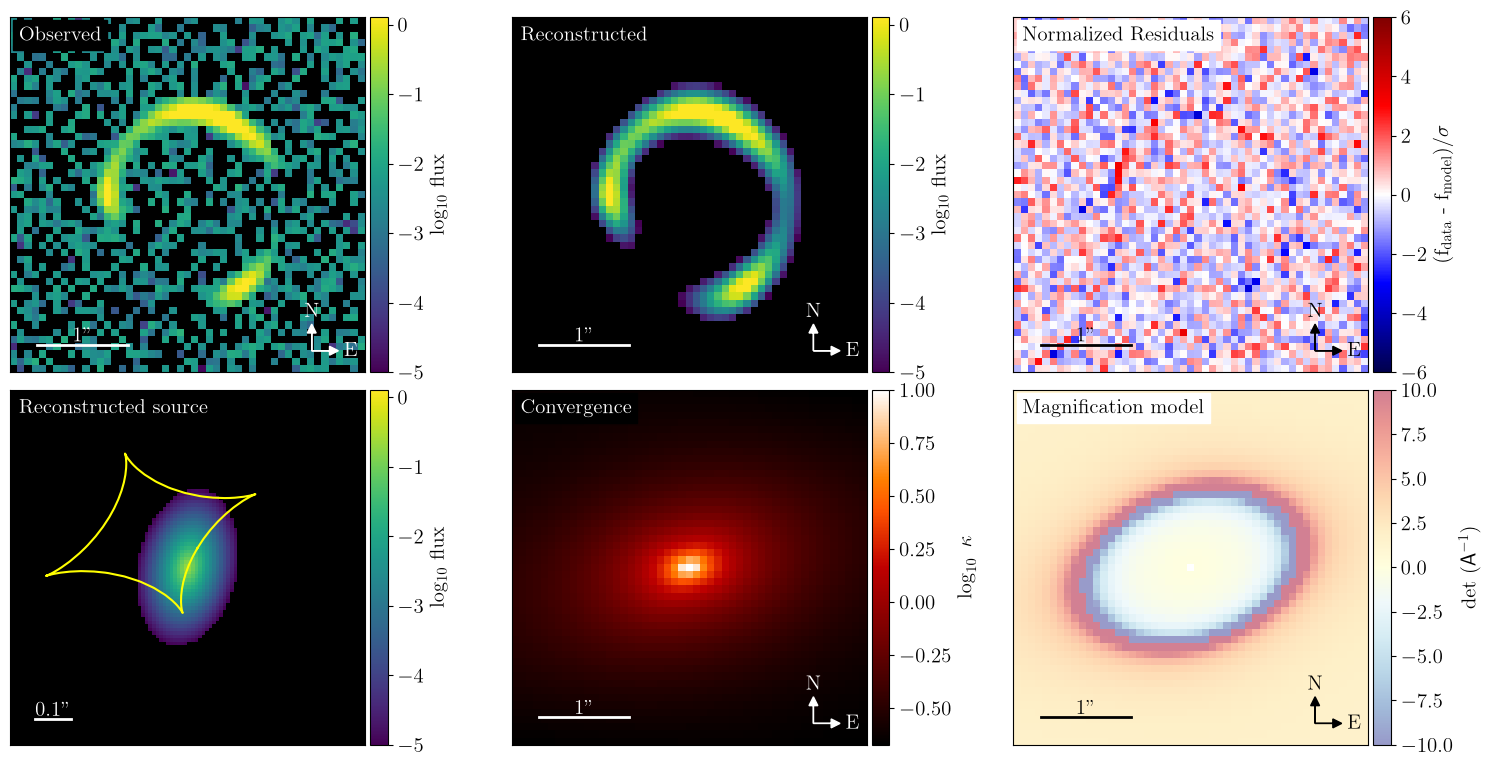

In [25]:
# analyse the MCMC and display best-fit image
from lenstronomy.Plots import chain_plot
from lenstronomy.Plots.model_plot import ModelPlot
from matplotlib import colormaps
cmap_default = colormaps['viridis'].with_extremes(under='k')
cmap_default.set_bad(color='black')

modelPlot = ModelPlot(multi_band_list, kwargs_model, kwargs_result)

f, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=False, sharey=False)

modelPlot.data_plot(ax=axes[0,0], kwargs_coordinate_arrows={"size":0.02}, vmin=-5, cmap=cmap_default)
modelPlot.model_plot(ax=axes[0,1], kwargs_coordinate_arrows={"size":0.02}, vmin=-5, cmap=cmap_default)
modelPlot.normalized_residual_plot(ax=axes[0,2], kwargs_coordinate_arrows={"size":0.02}, cmap="seismic", vmin=-6, vmax=6)
modelPlot.source_plot(ax=axes[1, 0], delta_pix_source=0.01, num_pix=100, vmin=-5, cmap=cmap_default)
modelPlot.convergence_plot(ax=axes[1, 1], vmax=1)
modelPlot.magnification_plot(ax=axes[1, 2])
f.tight_layout()
f.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0., hspace=0.05)
plt.show()

number of non-linear parameters in the MCMC process:  16
parameters in order:  ['e1_0_lens0', 'e2_0_lens0', 'e1_1_lens0', 'e2_1_lens0', 'v_x_lens0', 'v_y_lens0', 'theta_E_lens0', 'gamma_lens0', 'gamma1_lens1', 'gamma2_lens1', 'R_sersic_source_light0', 'n_sersic_source_light0', 'e1_source_light0', 'e2_source_light0', 'center_x_source_light0', 'center_y_source_light0']
number of evaluations in the MCMC process:  800000


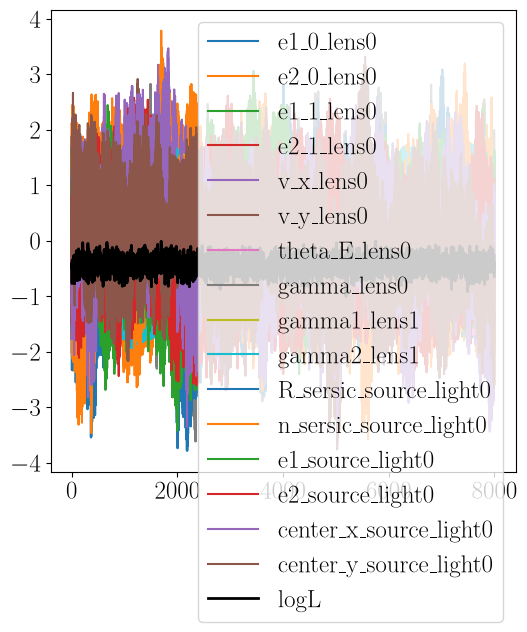

In [26]:
# convergence of the MCMC

for i in range(len(chain_list)):
    chain_plot.plot_chain_list(chain_list, i)
    
sampler_type, samples_mcmc, param_mcmc, dist_mcmc  = chain_list[0]

print("number of non-linear parameters in the MCMC process: ", len(param_mcmc))
print("parameters in order: ", param_mcmc)
print("number of evaluations in the MCMC process: ", np.shape(samples_mcmc)[0])

In [27]:
# Constraints on the parameters: define the labels and expected values

labels = [r'$e_{1, 0}$',
          r'$e_{2, 0}$',
          r'$e_{1, \zeta}$',
          r'$e_{2, \zeta}$',
          r'$v_x$',
          r'$v_y$',
          r'$\theta_{\rm E}$',
          r'$\gamma$',
          r'$\gamma_1$',
          r'$\gamma_2$',
          r'$R_{\rm Sérsic}$',
          r'$n_{\rm Sérsic}$',
          r'$e_1^{\rm source}$',
          r'$e_2^{\rm source}$',
          r'$x_{\rm source}$',
          r'$y_{\rm source}$']

expected_values = [kwargs_EPL['e1'],
                   kwargs_EPL['e2'],
                   0.0,
                   0.0,
                   0.0,
                   0.0,
                   kwargs_EPL['theta_E'],
                   kwargs_EPL['gamma'],
                   kwargs_shear['gamma1'],
                   kwargs_shear['gamma2'],
                   kwargs_sersic['R_sersic'],
                   kwargs_sersic['n_sersic'],
                   kwargs_sersic['e1'],
                   kwargs_sersic['e2'],
                   kwargs_sersic['center_x'],
                   kwargs_sersic['center_y']]

n, num_param = np.shape(samples_mcmc)

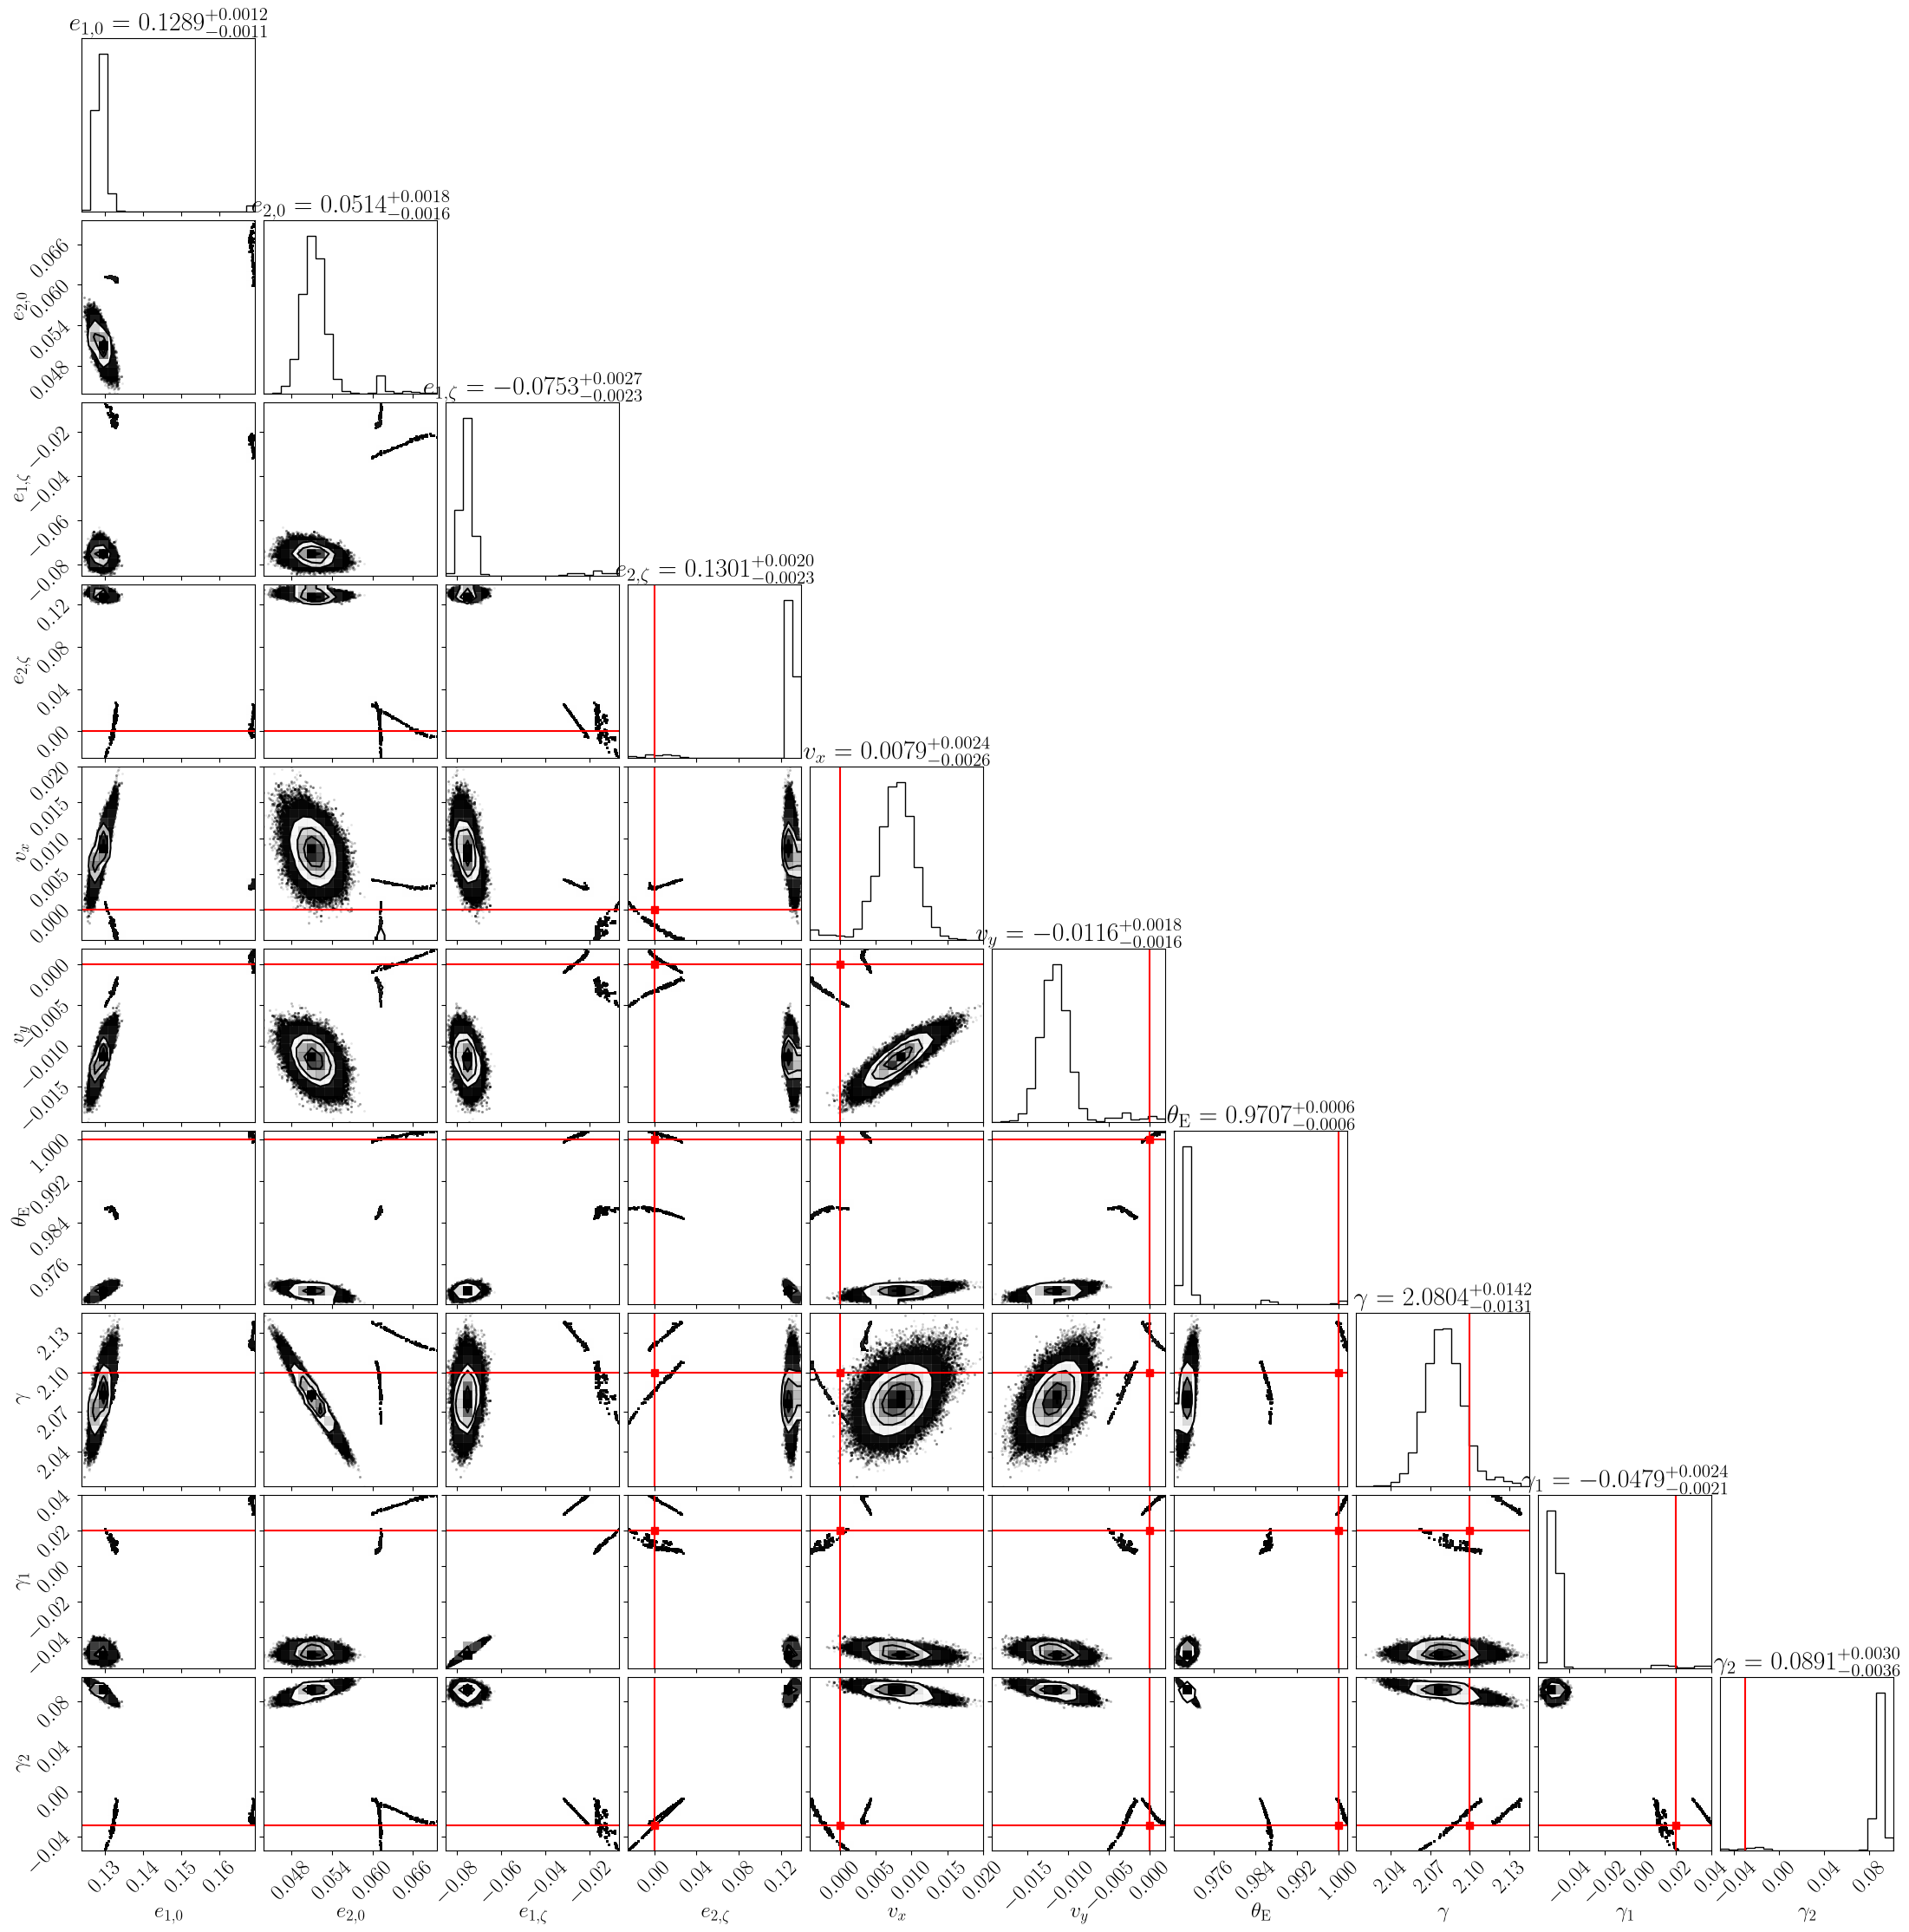

In [28]:
# have a look at the constraints on the line-of-sight parameters

plot = corner.corner(samples_mcmc[:,:10],
                     labels=labels[:10],
                     truths=expected_values[:10],
                     truth_color='r',
                     show_titles=True,
                     title_fmt = '.4f')